# Proyecto 2: ¿Se puede predecir un partido?

**Fuerza deportiva, economía y el resultado de los partidos internacionales (1960–2026)**

Data Science · Sección A · Segundo semestre 2026

**Autor:** Milton Beltrán
**Dataset:** International football results 1872–2026 (martj42) + World Development Indicators (Banco Mundial) + Population estimates (ONS, Reino Unido). Los mismos datos del Proyecto 1, mejorados.

| Criterio | Pts | Qué buscamos |
|---|---|---|
| Preparación y validación | 3 | El test se toca una sola vez; nada se filtra al modelo |
| Búsqueda de opciones y ensamble | 2 | Probaron opciones con razón, no al azar |
| Métrica e interpretación | 2 | Dicen por qué esa métrica y dónde se equivoca el modelo |
| Análisis sin respuestas | 2 | Cada grupo o eje tiene nombre y descripción |
| Límites | 1 | Qué no puede concluirse |

## 1. Pregunta y datos

El Proyecto 1 encontró que el PIB per cápita explica poco del desempeño anual de una selección (R² de test 0.147) y que la población pesa casi el doble que el dinero. Este proyecto baja de país-año a **partido** y hace una pregunta más dura: si ya se sabe qué tan fuerte es cada equipo en la cancha, ¿le queda algo por decir a la economía?

**Pregunta:** Antes de que se juegue un partido internacional, ¿se puede predecir si gana el local, empatan o gana la visita? Y si ya se conoce la fuerza deportiva de cada equipo (su rating Elo), ¿saber su PIB per cápita y su población mejora la predicción?

**Para quién y qué decisión cambiaría:** Una federación que busca planificar sus próximos partidos amistosos.

**Tipo de problema:** predecir una categoría (clasificación en tres clases).

**Columna que se quiere predecir:** `resultado` ∈ {`local`, `empate`, `visita`}, con el marcador de tiempo reglamentario más prórroga. Los penales no cuentan: un partido definido por penales es un empate.

**Qué representa una fila:** un partido internacional jugado desde 1960 en el que los dos equipos tienen PIB per cápita y población reportados ese año.

**Fuente, fecha de descarga y licencia:** las mismas tres fuentes del Proyecto 1, con las copias congeladas en `data/raw/`. La ficha completa está en `data/procedencia.json`.

| | Partidos | Economía | Población del Reino Unido |
|---|---|---|---|
| **Fuente** | [martj42/international_results](https://github.com/martj42/international_results) | [API del Banco Mundial](https://data.worldbank.org) | [ONS](https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates) |
| **Indicadores** | `results.csv` | `NY.GDP.PCAP.KD` (PIB per cápita, US$ constantes de 2015) y `SP.POP.TOTL` | Población a mitad de año de Inglaterra, Escocia, Gales e Irlanda del Norte |
| **Licencia** | CC0-1.0 (dominio público) | CC BY 4.0 | Open Government Licence v3.0 |
| **Fecha de descarga** | 2026-09-14 | 2026-09-14 | 2026-09-14 |

### Qué se mejoró respecto al Proyecto 1

| | Proyecto 1 | Proyecto 2 |
|---|---|---|
| **Unidad** | un país en un año | un partido |
| **Fuerza del rival** | `fuerza_rival`: promedio histórico de diferencia de goles, calculado con partidos futuros y de países de test (fuga declarada en el P1) | **Elo antes de cada partido**, calculado en orden cronológico: cada fila solo ve el pasado |
| **Validación** | partición por país, una sola vez | corte por fecha (test = partidos desde 2022) y validación cruzada temporal dentro del train |
| **Modelos** | trivial y regresión lineal | tonto, regresión logística y gradient boosting con búsqueda de opciones |

Se conserva la limpieza del P1: filtro de los 78 agregados del Banco Mundial, diccionario de 33 nombres, población del ONS con el PIB del Reino Unido para las cuatro naciones británicas y exclusión de las selecciones que no son países.

### El rating Elo

Se sigue la fórmula del [World Football Elo Ratings](https://www.eloratings.net/about). Todos los equipos arrancan en 1500 y después de cada partido intercambian puntos:

$$\text{cambio} = K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{10^{-\Delta/400} + 1}$$

- $W$ es el resultado real (1 gana, 0.5 empata, 0 pierde) y $W_e$ el esperado según la diferencia de ratings $\Delta$, a la que se le suman 100 puntos de ventaja si el local juega en casa.
- $K$ pesa la importancia del partido: 60 Mundial, 50 torneo continental, 40 eliminatorias y Nations League, 30 otros torneos, 20 amistosos.
- $G$ premia la goleada: 1 si se gana por uno, 1.5 por dos, $(11 + N)/8$ por tres o más.

El Elo se calcula recorriendo **todos** los partidos desde 1872, para que en 1960 los ratings ya estén calentados, y cada fila guarda el rating que cada equipo tenía **antes** de jugar ese partido.

In [7]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

ANCHO = 68

# encabezado de bloque, para que las salidas no se amontonen
def titulo(texto):
    print()
    print(texto)
    print("-" * ANCHO)

RANDOM_STATE = 42
RAW = Path("data/raw")

pd.set_option("display.width", 120)

In [8]:
# results.csv tal como viene: una fila por partido
def cargar_partidos():
    df = pd.read_csv(RAW / "results.csv", parse_dates=["date"])
    df["year"] = df["date"].dt.year
    return df


# un indicador del Banco Mundial, ya sin los 78 agregados
def cargar_indicador_bm(indicador, nombre):
    meta = json.loads((RAW / "wb_countries.json").read_text())[1]
    paises_reales = {c["name"] for c in meta if c["region"]["value"] != "Aggregates"}

    registros = json.loads((RAW / f"wb_{indicador}.json").read_text())[1]
    df = pd.DataFrame([
        {"wb_country": r["country"]["value"], "year": int(r["date"]), nombre: r["value"]}
        for r in registros
    ])
    return df[df["wb_country"].isin(paises_reales)].reset_index(drop=True)


# poblacion de las cuatro naciones britanicas, que el Banco Mundial no separa
def cargar_poblacion_ons():
    series = {"enpop": "England", "scpop": "Scotland",
              "wapop": "Wales", "nipop": "Northern Ireland"}
    filas = []
    for archivo, pais in series.items():
        datos = json.loads((RAW / f"ons_{archivo}.json").read_text())
        for obs in datos["years"]:
            filas.append({"team": pais, "year": int(obs["year"]),
                          "pop": float(obs["value"])})
    return pd.DataFrame(filas)


# las dos fuentes escriben distinto el mismo pais (diccionario del P1)
NOMBRES_BM = {
    "South Korea": "Korea, Rep.",          "North Korea": "Korea, Dem. People's Rep.",
    "Russia": "Russian Federation",        "Turkey": "Turkiye",
    "Ivory Coast": "Cote d'Ivoire",        "DR Congo": "Congo, Dem. Rep.",
    "Congo": "Congo, Rep.",                "Egypt": "Egypt, Arab Rep.",
    "Iran": "Iran, Islamic Rep.",          "Venezuela": "Venezuela, RB",
    "Syria": "Syrian Arab Republic",       "Yemen": "Yemen, Rep.",
    "Laos": "Lao PDR",                     "Cape Verde": "Cabo Verde",
    "Vietnam": "Viet Nam",                 "Kyrgyzstan": "Kyrgyz Republic",
    "Slovakia": "Slovak Republic",         "Czech Republic": "Czechia",
    "Gambia": "Gambia, The",               "Bahamas": "Bahamas, The",
    "Hong Kong": "Hong Kong SAR, China",   "Macau": "Macao SAR, China",
    "Brunei": "Brunei Darussalam",         "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",            "Republic of Ireland": "Ireland",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "São Tomé and Príncipe": "Sao Tome and Principe",
    "Palestine": "West Bank and Gaza",     "Curaçao": "Curacao",
    "United States Virgin Islands": "Virgin Islands (U.S.)",
    "Saint Martin": "St. Martin (French part)",
    "Micronesia": "Micronesia, Fed. Sts.",
}

BRITANICAS = ["England", "Scotland", "Wales", "Northern Ireland"]

NO_PAISES = ["Ynys Môn", "Shetland", "Orkney", "Isle of Wight", "Padania", "Sápmi",
             "Frøya", "Saare County", "Western Isles", "Gotland", "Menorca",
             "Provence", "Alderney", "Åland Islands", "Jersey", "Guernsey"]


# PIB per capita y poblacion por (equipo, año), con la regla del P1 para las britanicas:
# poblacion real del ONS y PIB per capita del Reino Unido completo
def economia_por_equipo(equipos):
    eco_bm = gdppc.merge(poblacion, on=["wb_country", "year"]).dropna()

    base = pd.DataFrame({"team": sorted(set(equipos) - set(BRITANICAS))})
    base["wb_country"] = base["team"].map(NOMBRES_BM).fillna(base["team"])
    resto = base.merge(eco_bm, on="wb_country")[["team", "year", "gdppc", "pop"]]

    pib_uk = eco_bm.loc[eco_bm["wb_country"] == "United Kingdom", ["year", "gdppc"]]
    britanicas = pop_uk.merge(pib_uk, on="year")[["team", "year", "gdppc", "pop"]]

    return pd.concat([resto, britanicas], ignore_index=True)


partidos = cargar_partidos()
gdppc = cargar_indicador_bm("NY.GDP.PCAP.KD", "gdppc")
poblacion = cargar_indicador_bm("SP.POP.TOTL", "pop")
pop_uk = cargar_poblacion_ons()

titulo("FUENTES CARGADAS")
print(f"  {'partidos':<12} {partidos.shape[0]:>7,} filas  ({partidos['date'].min().date()} a {partidos['date'].max().date()})")
print(f"  {'gdppc':<12} {gdppc.shape[0]:>7,} filas  ({gdppc['wb_country'].nunique()} países)")
print(f"  {'población':<12} {poblacion.shape[0]:>7,} filas")
print(f"  {'pop_uk':<12} {pop_uk.shape[0]:>7,} filas  ({', '.join(sorted(pop_uk['team'].unique()))})")


FUENTES CARGADAS
--------------------------------------------------------------------
  partidos      49,547 filas  (1872-11-30 a 2026-08-26)
  gdppc         14,322 filas  (217 países)
  población     14,322 filas
  pop_uk           216 filas  (England, Northern Ireland, Scotland, Wales)


In [9]:
CONTINENTALES = {"Copa América", "UEFA Euro", "African Cup of Nations", "AFC Asian Cup",
                 "Gold Cup", "CONCACAF Championship", "Oceania Nations Cup",
                 "Confederations Cup"}

def tipo_torneo(nombre):
    if nombre == "Friendly":
        return "amistoso"
    if nombre == "FIFA World Cup":
        return "mundial"
    if nombre in CONTINENTALES:
        return "continental"
    if "qualification" in nombre or "Nations League" in nombre:
        return "eliminatoria"
    return "otro"


# K del World Football Elo segun la importancia del partido
K_POR_TIPO = {"mundial": 60, "continental": 50, "eliminatoria": 40, "otro": 30, "amistoso": 20}
ELO_INICIAL = 1500
VENTAJA_LOCAL = 100


def multiplicador_goles(dif):
    n = abs(dif)
    if n <= 1:
        return 1.0
    if n == 2:
        return 1.5
    return (11 + n) / 8


# recorre los partidos en orden cronologico y guarda el Elo de cada equipo ANTES de jugar.
# el resultado de un partido solo afecta a los partidos que vienen despues.
def calcular_elo(partidos):
    orden = partidos.sort_values("date", kind="stable")
    rating = {}
    antes_local, antes_visita = [], []

    for local, visita, gl, gv, neutral, k in zip(
            orden["home_team"], orden["away_team"], orden["home_score"],
            orden["away_score"], orden["neutral"], orden["tipo_torneo"].map(K_POR_TIPO)):
        r_local = rating.get(local, ELO_INICIAL)
        r_visita = rating.get(visita, ELO_INICIAL)
        antes_local.append(r_local)
        antes_visita.append(r_visita)

        delta = r_local - r_visita + (0 if neutral else VENTAJA_LOCAL)
        esperado = 1 / (10 ** (-delta / 400) + 1)
        real = 1.0 if gl > gv else 0.5 if gl == gv else 0.0

        cambio = k * multiplicador_goles(gl - gv) * (real - esperado)
        rating[local] = r_local + cambio
        rating[visita] = r_visita - cambio

    elo = pd.DataFrame({"elo_local": antes_local, "elo_visita": antes_visita}, index=orden.index)
    return elo, pd.Series(rating).sort_values(ascending=False)


partidos["tipo_torneo"] = partidos["tournament"].map(tipo_torneo)
elo, elo_actual = calcular_elo(partidos)
partidos = partidos.join(elo)

titulo("TOP 10 DEL ELO DESPUÉS DEL ÚLTIMO PARTIDO DEL DATASET")
for pos, (equipo, r) in enumerate(elo_actual.head(10).items(), start=1):
    print(f"  {pos:>2}. {equipo:<20} {r:>7.0f}")
print(f"  ...  Guatemala en el puesto {elo_actual.index.get_loc('Guatemala') + 1} "
      f"con {elo_actual['Guatemala']:.0f}")


TOP 10 DEL ELO DESPUÉS DEL ÚLTIMO PARTIDO DEL DATASET
--------------------------------------------------------------------
   1. Spain                   2327
   2. Argentina               2250
   3. England                 2199
   4. France                  2141
   5. Colombia                2087
   6. Brazil                  2077
   7. Portugal                2060
   8. Netherlands             2046
   9. Morocco                 2030
  10. Belgium                 2027
  ...  Guatemala en el puesto 90 con 1647


In [10]:
# una fila por partido desde 1960, con la economia de los dos equipos ese año
eco = economia_por_equipo(set(partidos["home_team"]) | set(partidos["away_team"]))
eco_local = eco.rename(columns={"team": "home_team", "gdppc": "pib_local", "pop": "pob_local"})
eco_visita = eco.rename(columns={"team": "away_team", "gdppc": "pib_visita", "pop": "pob_visita"})

desde_1960 = partidos[(partidos["year"] >= 1960)
                      & ~partidos["home_team"].isin(NO_PAISES)
                      & ~partidos["away_team"].isin(NO_PAISES)]

df = (desde_1960
      .merge(eco_local, on=["home_team", "year"])
      .merge(eco_visita, on=["away_team", "year"])
      .sort_values("date", kind="stable")
      .reset_index(drop=True))

df["dif_elo"] = df["elo_local"] - df["elo_visita"]
df["dif_log_pib"] = np.log(df["pib_local"]) - np.log(df["pib_visita"])
df["dif_log_pob"] = np.log(df["pob_local"]) - np.log(df["pob_visita"])
df["resultado"] = np.select([df["home_score"] > df["away_score"],
                             df["home_score"] < df["away_score"]],
                            ["local", "visita"], default="empate")

titulo("DATASET DE PARTIDOS")
print(f"  {'partidos desde 1960':<36} {len(desde_1960):>7,}")
print(f"  {'con economía de los dos equipos':<36} {len(df):>7,}  ({len(df) / len(desde_1960):.1%})")
print(f"  {'equipos':<36} {pd.concat([df['home_team'], df['away_team']]).nunique():>7}")
print(f"  {'rango':<36} {df['date'].min().date()} a {df['date'].max().date()}")

# Verificacion: cada fila guarda el Elo de ANTES del partido, asi que el primer partido
# de la historia y el debut de Guatemala tienen que arrancar exactamente en el rating inicial
assert (partidos.loc[0, ["elo_local", "elo_visita"]] == ELO_INICIAL).all()
debut = partidos[(partidos["home_team"] == "Guatemala") | (partidos["away_team"] == "Guatemala")].iloc[0]
assert (debut["elo_local"] if debut["home_team"] == "Guatemala" else debut["elo_visita"]) == ELO_INICIAL

df.head()


DATASET DE PARTIDOS
--------------------------------------------------------------------
  partidos desde 1960                   43,942
  con economía de los dos equipos       36,678  (83.5%)
  equipos                                  207
  rango                                1960-01-06 a 2025-12-31


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,year,...,elo_local,elo_visita,pib_local,pob_local,pib_visita,pob_visita,dif_elo,dif_log_pib,dif_log_pob,resultado
0,1960-01-06,Italy,Switzerland,3,0,Central European International Cup,Naples,Italy,False,1960,...,1645.715627,1425.691956,9731.196278,50199700.0,36945.468660,5327827.0,220.023671,-1.334106,2.243066,local
1,1960-02-07,Ghana,Sierra Leone,6,2,Friendly,Accra,Ghana,False,1960,...,1543.594106,1466.696020,1100.763052,6961215.0,884.057110,2268356.0,76.898086,0.219237,1.121299,local
2,1960-02-28,Belgium,France,1,0,Friendly,Brussels,Belgium,False,1960,...,1488.911275,1781.478530,11715.826760,9153489.0,10776.123361,47412964.0,-292.567255,0.083608,-1.644761,local
3,1960-03-06,Brazil,Mexico,2,2,Pan American Championship,San José,Costa Rica,True,1960,...,1868.289196,1640.167651,2603.519010,72388126.0,4145.793022,36724615.0,228.121546,-0.465230,0.678595,empate
4,1960-03-08,Costa Rica,Argentina,0,0,Pan American Championship,San José,Costa Rica,False,1960,...,1728.574904,1818.933731,3616.303882,1327496.0,7397.109655,20386045.0,-90.358826,-0.715637,-2.731556,empate


## 2. Mirada rápida a los datos

Lo justo para decidir cómo modelar; el análisis exploratorio de las fuentes ya está en el Proyecto 1. Los tamaños y el reparto de clases se reportan para train y test, pero **las relaciones entre columnas se miran solo en el train** (partidos antes de 2022): lo que se aprenda mirando el test ya sería elegir con el test.

In [11]:
CORTE_TEST = pd.Timestamp("2022-01-01")   # todo lo que va desde aqui es test (seccion 3)
es_train = df["date"] < CORTE_TEST

COLUMNAS_MODELO = ["elo_local", "elo_visita", "dif_elo", "dif_log_pib", "dif_log_pob",
                   "neutral", "tipo_torneo"]

titulo("TAMAÑO Y HUECOS")
print(f"  {len(df):,} partidos  ->  train {es_train.sum():,}  /  test {(~es_train).sum():,}")
print(f"  huecos en las columnas del modelo: {int(df[COLUMNAS_MODELO].isna().sum().sum())}")

perdidos = len(desde_1960) - len(df)
de_2026 = int((desde_1960["year"] == 2026).sum())
titulo("QUÉ SE PIERDE AL UNIR CON LA ECONOMÍA")
print(f"  {'partidos perdidos':<40} {perdidos:>6,}")
print(f"  {'  de 2026 (el BM aún no publica 2026)':<40} {de_2026:>6,}")
print(f"  {'  equipo sin PIB o población ese año':<40} {perdidos - de_2026:>6,}")

parte = pd.Series(np.where(es_train, "train 1960–2021", "test 2022–2025"), index=df.index)
reparto = (pd.crosstab(parte, df["resultado"], normalize="index")[["local", "empate", "visita"]]
           .rename_axis(index=None, columns=None))
titulo("REPARTO DEL RESULTADO")
print((reparto * 100).round(1).sort_index(ascending=False).to_string())

tr = df[es_train]
por_cancha = pd.crosstab(np.where(tr["neutral"], "cancha neutral", "con local"),
                         tr["resultado"], normalize="index")[["local", "empate", "visita"]]
por_cancha = por_cancha.rename_axis(index=None, columns=None)
titulo("REPARTO EN TRAIN, SEGÚN LA CANCHA")
print((por_cancha * 100).round(1).to_string())

por_torneo = pd.crosstab(tr["tipo_torneo"], tr["resultado"], normalize="index")["empate"]
titulo("PROPORCIÓN DE EMPATES EN TRAIN, POR TIPO DE TORNEO")
for tipo, pct in por_torneo.sort_values().items():
    print(f"  {tipo:<14} {pct:>6.1%}   ({(tr['tipo_torneo'] == tipo).sum():>6,} partidos)")


TAMAÑO Y HUECOS
--------------------------------------------------------------------
  36,678 partidos  ->  train 33,121  /  test 3,557
  huecos en las columnas del modelo: 0

QUÉ SE PIERDE AL UNIR CON LA ECONOMÍA
--------------------------------------------------------------------
  partidos perdidos                         7,264
    de 2026 (el BM aún no publica 2026)       447
    equipo sin PIB o población ese año      6,817

REPARTO DEL RESULTADO
--------------------------------------------------------------------
                 local  empate  visita
train 1960–2021   48.6    24.3    27.1
test 2022–2025    47.4    23.9    28.7

REPARTO EN TRAIN, SEGÚN LA CANCHA
--------------------------------------------------------------------
                local  empate  visita
cancha neutral   42.8    24.3    32.9
con local        50.5    24.3    25.2

PROPORCIÓN DE EMPATES EN TRAIN, POR TIPO DE TORNEO
--------------------------------------------------------------------
  eliminatoria    

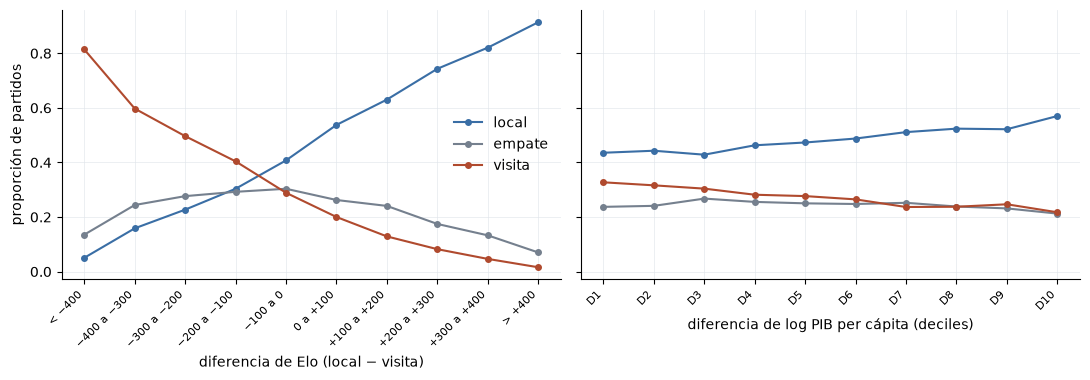


LOS EXTREMOS DE CADA GRÁFICA (train)
--------------------------------------------------------------------
                               local  empate  visita
  Elo < −400                    5.1%   13.5%   81.4%
  Elo entre −100 y +100        47.3%   28.3%   24.4%
  Elo > +400                   91.4%    7.0%    1.6%
  PIB decil 1                  43.6%   23.7%   32.7%
  PIB decil 10                 57.0%   21.3%   21.7%

¿EL DINERO YA ESTÁ DENTRO DEL ELO? (correlaciones en train)
--------------------------------------------------------------------
  dif_elo vs dif_log_pib    0.120
  dif_elo vs dif_log_pob    0.479
  dif_log_pib vs dif_log_pob -0.275


In [12]:
# la relacion que importa: como cambia el resultado con la diferencia de fuerza y de economia
cortes_elo = [-np.inf, -400, -300, -200, -100, 0, 100, 200, 300, 400, np.inf]
etiquetas_elo = ["< −400", "−400 a −300", "−300 a −200", "−200 a −100", "−100 a 0",
                 "0 a +100", "+100 a +200", "+200 a +300", "+300 a +400", "> +400"]
tramos = [
    (pd.cut(tr["dif_elo"], cortes_elo, labels=etiquetas_elo),
     etiquetas_elo, "diferencia de Elo (local − visita)"),
    (pd.qcut(tr["dif_log_pib"], 10, labels=[f"D{i}" for i in range(1, 11)]),
     [f"D{i}" for i in range(1, 11)], "diferencia de log PIB per cápita (deciles)"),
]

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
proporciones = []
for ax, (tramo, etiquetas, nombre) in zip(ejes, tramos):
    prop = pd.crosstab(tramo, tr["resultado"], normalize="index")[["local", "empate", "visita"]]
    proporciones.append(prop)
    for clase, color in [("local", AZUL), ("empate", GRIS), ("visita", ROJO)]:
        ax.plot(range(len(prop)), prop[clase], marker="o", ms=4, color=color, label=clase)
    ax.set_xticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
    ax.set_xlabel(nombre)
    eje_limpio(ax)
ejes[0].set_ylabel("proporción de partidos")
ejes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

prop_elo, prop_pib = proporciones
titulo("LOS EXTREMOS DE CADA GRÁFICA (train)")
print(f"  {'':<26} {'local':>7} {'empate':>7} {'visita':>7}")
for nombre, fila in [("Elo < −400", prop_elo.iloc[0]), ("Elo entre −100 y +100", None),
                     ("Elo > +400", prop_elo.iloc[-1]),
                     ("PIB decil 1", prop_pib.iloc[0]), ("PIB decil 10", prop_pib.iloc[-1])]:
    if fila is None:
        cerca = tr[tr["dif_elo"].abs() < 100]["resultado"].value_counts(normalize=True)
        fila = cerca.reindex(["local", "empate", "visita"])
    print(f"  {nombre:<26} {fila['local']:>7.1%} {fila['empate']:>7.1%} {fila['visita']:>7.1%}")

titulo("¿EL DINERO YA ESTÁ DENTRO DEL ELO? (correlaciones en train)")
c = tr[["dif_elo", "dif_log_pib", "dif_log_pob"]].corr()
print(f"  dif_elo vs dif_log_pib   {c.loc['dif_elo', 'dif_log_pib']:>6.3f}")
print(f"  dif_elo vs dif_log_pob   {c.loc['dif_elo', 'dif_log_pob']:>6.3f}")
print(f"  dif_log_pib vs dif_log_pob {c.loc['dif_log_pib', 'dif_log_pob']:>4.3f}")

**Lo que importa de este dataset para modelar:** 

1. El local gana el 48.6% de los partidos, así que el modelo tonto saca casi 50% de aciertos sin saber nada de fútbol. El reparto casi no cambia en el test (47.4% local, 23.9% empate, 28.7% visita), así que cortar por fecha no deja un examen raro. Por eso la métrica es F1 macro y no accuracy, que obliga a acertar las tres clases y no solo la más común.

2. El Elo es la señal más fuerte: con más de 400 puntos a favor el local gana el 91.4%, y con más de 400 en contra la visita gana el 81.4%. El empate nunca pasa del 30%, y su punto más alto está en −100, donde la ventaja de jugar en casa empareja a los dos equipos. Ahí las tres clases quedan casi iguales, así que el modelo casi nunca va a elegir empate, y neutral tiene que entrar porque cambia dónde está el partido parejo.

3. La economía mueve poco el resultado: del decil 1 al 10 de PIB, la victoria local solo sube de 43.6% a 57.0%. Además, la población correlaciona 0.479 con la diferencia de Elo, así que buena parte de lo que aportaba en el P1 ya viene dentro del rating. Lo esperable es que el PIB y la población agreguen poco sobre el Elo, pero eso se mide en la validación cruzada, no se supone.

## 3. Separar y preparar

Los partidos tienen fecha, así que **no se barajan**: se corta por fecha. Todo lo jugado antes de 2022 es train y todo desde 2022 es test. Barajar dejaría que el modelo aprenda con partidos de 2024 para predecir uno de 2019, algo que nunca podría pasar al usar el modelo de verdad.

La validación cruzada dentro del train sigue la misma regla con `TimeSeriesSplit`: en cada vuelta se entrena con el pasado y se valida con el bloque de años que viene justo después.

In [14]:
from sklearn.model_selection import TimeSeriesSplit

TARGET = "resultado"
NUMERICAS = ["elo_local", "elo_visita", "dif_elo", "dif_log_pib", "dif_log_pob"]
CATEGORICAS = ["tipo_torneo"]
BINARIAS = ["neutral"]
ECONOMICAS = ["dif_log_pib", "dif_log_pob"]   # las que se quitan para medir si el dinero agrega algo

# df ya viene ordenado por fecha (seccion 1), y el orden se conserva al cortar
train = df[df["date"] < CORTE_TEST]
test = df[df["date"] >= CORTE_TEST]

X_tr, y_tr = train[NUMERICAS + CATEGORICAS + BINARIAS], train[TARGET]
X_te, y_te = test[NUMERICAS + CATEGORICAS + BINARIAS], test[TARGET]

cv = TimeSeriesSplit(n_splits=5)

titulo("CORTE POR FECHA")
print(f"  {'train':<6} {len(train):>7,} partidos   {train['date'].min().date()} a {train['date'].max().date()}")
print(f"  {'test':<6} {len(test):>7,} partidos   {test['date'].min().date()} a {test['date'].max().date()}")

titulo("VALIDACIÓN CRUZADA TEMPORAL DENTRO DEL TRAIN")
print(f"  {'vuelta':<8} {'entrena con':<16} {'valida con':<16} {'n valida':>9}")
for vuelta, (i_ent, i_val) in enumerate(cv.split(X_tr), start=1):
    a = train["year"].iloc[i_ent]
    b = train["year"].iloc[i_val]
    print(f"  {vuelta:<8} {f'{a.min()}–{a.max()}':<16} {f'{b.min()}–{b.max()}':<16} {len(i_val):>9,}")

# Verificacion: ningun partido de test es anterior al ultimo de train
assert train["date"].max() < test["date"].min()


CORTE POR FECHA
--------------------------------------------------------------------
  train   33,121 partidos   1960-01-06 a 2021-12-31
  test     3,557 partidos   2022-01-01 a 2025-12-31

VALIDACIÓN CRUZADA TEMPORAL DENTRO DEL TRAIN
--------------------------------------------------------------------
  vuelta   entrena con      valida con        n valida
  1        1960–1982        1982–1994            5,520
  2        1960–1994        1994–2001            5,520
  3        1960–2001        2001–2008            5,520
  4        1960–2008        2008–2015            5,520
  5        1960–2015        2015–2021            5,520


In [15]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


def armar_preparacion(numericas):
    return ColumnTransformer([
        ("num", Pipeline([("rellenar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
        ("bin", "passthrough", BINARIAS),
    ])


preparacion = armar_preparacion(NUMERICAS)
# la misma receta sin las columnas economicas, para la comparacion de la seccion 5
preparacion_sin_eco = armar_preparacion([c for c in NUMERICAS if c not in ECONOMICAS])

# solo para mostrar que sale: se ajusta una COPIA con el train. La preparacion de verdad se
# ajusta dentro de cada Pipeline, en cada vuelta de la validacion, nunca sobre el test.
muestra = clone(preparacion).fit(X_tr)
nombres = muestra.get_feature_names_out()

titulo("LO QUE LE LLEGA AL MODELO")
print(f"  {len(nombres)} columnas a partir de {X_tr.shape[1]}:")
for nombre in nombres:
    print(f"    {nombre}")


LO QUE LE LLEGA AL MODELO
--------------------------------------------------------------------
  11 columnas a partir de 7:
    num__elo_local
    num__elo_visita
    num__dif_elo
    num__dif_log_pib
    num__dif_log_pob
    cat__tipo_torneo_amistoso
    cat__tipo_torneo_continental
    cat__tipo_torneo_eliminatoria
    cat__tipo_torneo_mundial
    cat__tipo_torneo_otro
    bin__neutral


**Por qué se preparó así:**

- **Rellenos con la mediana.** Hoy no hay ningún hueco en las columnas del modelo, pero el relleno queda dentro del `Pipeline` para que un partido nuevo con un dato faltante no rompa el modelo. Si llegara a usarse, la mediana se calcula solo con el train de cada vuelta.

- **Numéricas escaladas.** La regresión logística compara coeficientes y penaliza su tamaño, así que necesita las columnas en la misma escala: el Elo se mide en cientos de puntos y las diferencias de log en unidades. Al boosting no le cambia nada, pero se usa la misma receta para que los modelos se comparen en igualdad de condiciones.

- **`tipo_torneo` en one-hot.** Son cinco categorías sin orden entre ellas (un Mundial no es "dos amistosos"), y `handle_unknown="ignore"` evita que el modelo se rompa si aparece un tipo nuevo.

- **Se dejan `elo_local` y `elo_visita` además de `dif_elo`.** La diferencia dice quién es favorito, pero el nivel también importa: un partido entre dos equipos de 2000 puntos no se juega igual que uno entre dos de 1400, aunque la diferencia sea la misma.

- **Hay una segunda receta sin `dif_log_pib` ni `dif_log_pob`.** Es la que permite responder la segunda pregunta del proyecto en la sección 5: el mismo modelo con y sin economía, medido en la misma validación.

## 4. Modelos de comparación

*Dos puntos de comparación obligatorios: el modelo tonto (siempre el promedio, o siempre la categoría más común) y un modelo simple. Sin ellos, el número del ensamble no significa nada.*

In [ ]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.model_selection import cross_val_score

# Modelo tonto, con validación cruzada sobre los datos de entrenamiento
...

In [ ]:
# Modelo simple: Pipeline(preparacion + regresión logística o árbol chico), con cross_val_score
...

**Métrica elegida y por qué:** *(¿qué error cuesta más: una falsa alarma o un escape? Si predicen un número, ¿castigar más los errores grandes o tratar todos igual?)*

## 5. Ensamble y búsqueda de opciones

*Al menos un ensamble (bosque o boosting). El `Pipeline` completo va dentro del buscador, para que cada vuelta de la validación prepare los datos de nuevo. Digan qué opciones probaron, en qué rango y por qué.*

In [ ]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

pipe = Pipeline([("prep", preparacion), ("modelo", ...)])

opciones = {
    # "modelo__n_estimators": [...],
    # "modelo__max_depth": [...],
}

busqueda = ...
# busqueda.fit(X_tr, y_tr)
# print(busqueda.best_params_, busqueda.best_score_)

**Qué se probó y por qué ese rango:**

**Mejor combinación y su puntaje en validación:**

## 6. Evaluación final

*Aquí, y solo aquí, se toca el test. Una vez. Después de esta celda no se ajusta nada.*

In [ ]:
# Métrica principal en test
...

# Dónde se equivoca: tabla de aciertos y errores, o errores contra lo predicho. ¿Hay un patrón?
...

**Comparación contra los modelos de comparación:**

| Modelo | Métrica (validación) | Métrica (test) |
|---|---|---|
| Tonto | | |
| Simple | | |
| Ensamble | | |

**Dónde falla el modelo:**

## 7. Análisis sin respuestas

*Elijan **una** ruta. Escalar es obligatorio en ambas.*

- **Ruta A, agrupar**: k-Means, jerárquico o DBSCAN. Justifiquen el número de grupos (silhouette **y** sentido para el negocio) y describan cada grupo.
- **Ruta B, resumir columnas**: PCA (t-SNE solo para mirar). Cuánta información conservan los ejes y qué columnas pesan en los primeros dos.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Ruta A o Ruta B (escalando primero)
...

# Describir: promedios por grupo, o qué columnas pesan en cada eje
...

**Interpretación** *(un grupo sin nombre es un grupo que no interpretaron)*:

| Grupo | Nombre en palabras del negocio | Qué lo caracteriza | Tamaño |
|---|---|---|---|
| 0 | | | |
| 1 | | | |
| 2 | | | |

## 8. Conexión entre las dos partes

*Lo que distingue un buen Proyecto 2 de dos tareas pegadas. Por ejemplo: ¿el modelo se equivoca más en algún grupo? ¿Los ejes de PCA coinciden con las columnas más importantes del modelo? ¿Los grupos sugieren una columna nueva?*

In [ ]:
# Cruzar los grupos o ejes con los aciertos y errores del modelo
...

**Lo que aprendimos al cruzar ambas partes:**

## 9. Conclusiones y límites

*Tres párrafos cortos:*

1. *La respuesta a la pregunta de la sección 1, con su número y qué tan seguro es.*
2. *Qué **no** se puede concluir: sesgos del dataset, poblaciones que no aparecen, causas que no se pueden afirmar.*
3. *Qué haría falta para mejorarlo.*

## 10. Lista antes de entregar

- [ ] ¿Todo lo que se calcula con los datos está **dentro** del `Pipeline`, y el `Pipeline` dentro de la validación?
- [ ] ¿Está escrito **por qué** esa métrica?
- [ ] ¿Hay modelo tonto y modelo simple para comparar?
- [ ] ¿La búsqueda de opciones dice qué, en qué rango y por qué?
- [ ] ¿Cada grupo tiene nombre y descripción en palabras del negocio?
- [ ] ¿El test se tocó una sola vez?
- [ ] ¿Hay un párrafo de lo que **no** se puede concluir?
- [ ] ¿El notebook corre de arriba a abajo sin errores (`Restart & Run All`)?
- [ ] ¿Incluye la bitácora de colaboración si usaron AI?

**Entrega: viernes 16 de octubre.** Parcial II: jueves 22 de octubre (sesiones 11 a 21).